# Rotated surface-code shrink

**[DEMO]** — Prepare → source SE → shrink → target SE → readout.

`shrink` measures the removed data and updates the registered patch. A fresh,
ordinary SE block is then constructed from that updated system. `ROUNDS = 1`
shows one target SE round with four CNOT layers; use `0` to omit it.

Below, `get_info()` prints the old input snapshot and the returned smaller patch.
Logical Pauli strings use retained global qubit IDs. Measurement-dependent
logical signs remain in the tracker’s record parities.


In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "lightstim").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from lightstim.protocols import RotatedSurfaceShrinkExperiment

In [2]:
DISTANCE = 5
TARGET_DISTANCE = 3
DIRECTION = "-x,-y"
ROUNDS = 1  # Ordinary target-code SE rounds after shrink
SOURCE_ROUNDS = 1
INITIAL_BASIS = "X"  # "X" or "Z"

In [3]:
experiment = RotatedSurfaceShrinkExperiment(
    distance=DISTANCE,
    target_distance=TARGET_DISTANCE,
    direction=DIRECTION,
    rounds=ROUNDS,
    source_rounds=SOURCE_ROUNDS,
    basis=INITIAL_BASIS,
)
circuit = experiment.build()

In [4]:
patch = experiment.output_patch  # Use the returned view after deformation.
before = experiment.source_patch.get_info()
after = patch.get_info()
registered = experiment.system.patches["patch"][0].get_info()

print(f"{'Patch':<17} {'d_X':>4} {'d_Z':>4} {'Data':>6} {'X checks':>9} {'Z checks':>9}")
for label, info in (("Before shrink", before), ("After shrink", after)):
    print(f"{label:<17} {info['distance_x']:>4} {info['distance_z']:>4} "
          f"{info['num_data_qubits']:>6} {info['num_x_syndromes']:>9} {info['num_z_syndromes']:>9}")
print(f"\nRegistered patch: d_X={registered['distance_x']}, d_Z={registered['distance_z']}")
for basis in ("X", "Z"):
    operator = next(op for op in after["logical_ops"] if op["type"] == basis)
    pauli = " * ".join(f"{axis}{q}" for q, axis in sorted(operator["pauli"].items()))
    print(f"Logical {basis}: {pauli}  (weight {len(operator['pauli'])})")


Patch              d_X  d_Z   Data  X checks  Z checks
Before shrink        5    5     25        12        12
After shrink         3    3      9         4         4

Registered patch: d_X=3, d_Z=3
Logical X: X2 * X12 * X22  (weight 3)
Logical Z: Z2 * Z3 * Z4  (weight 3)


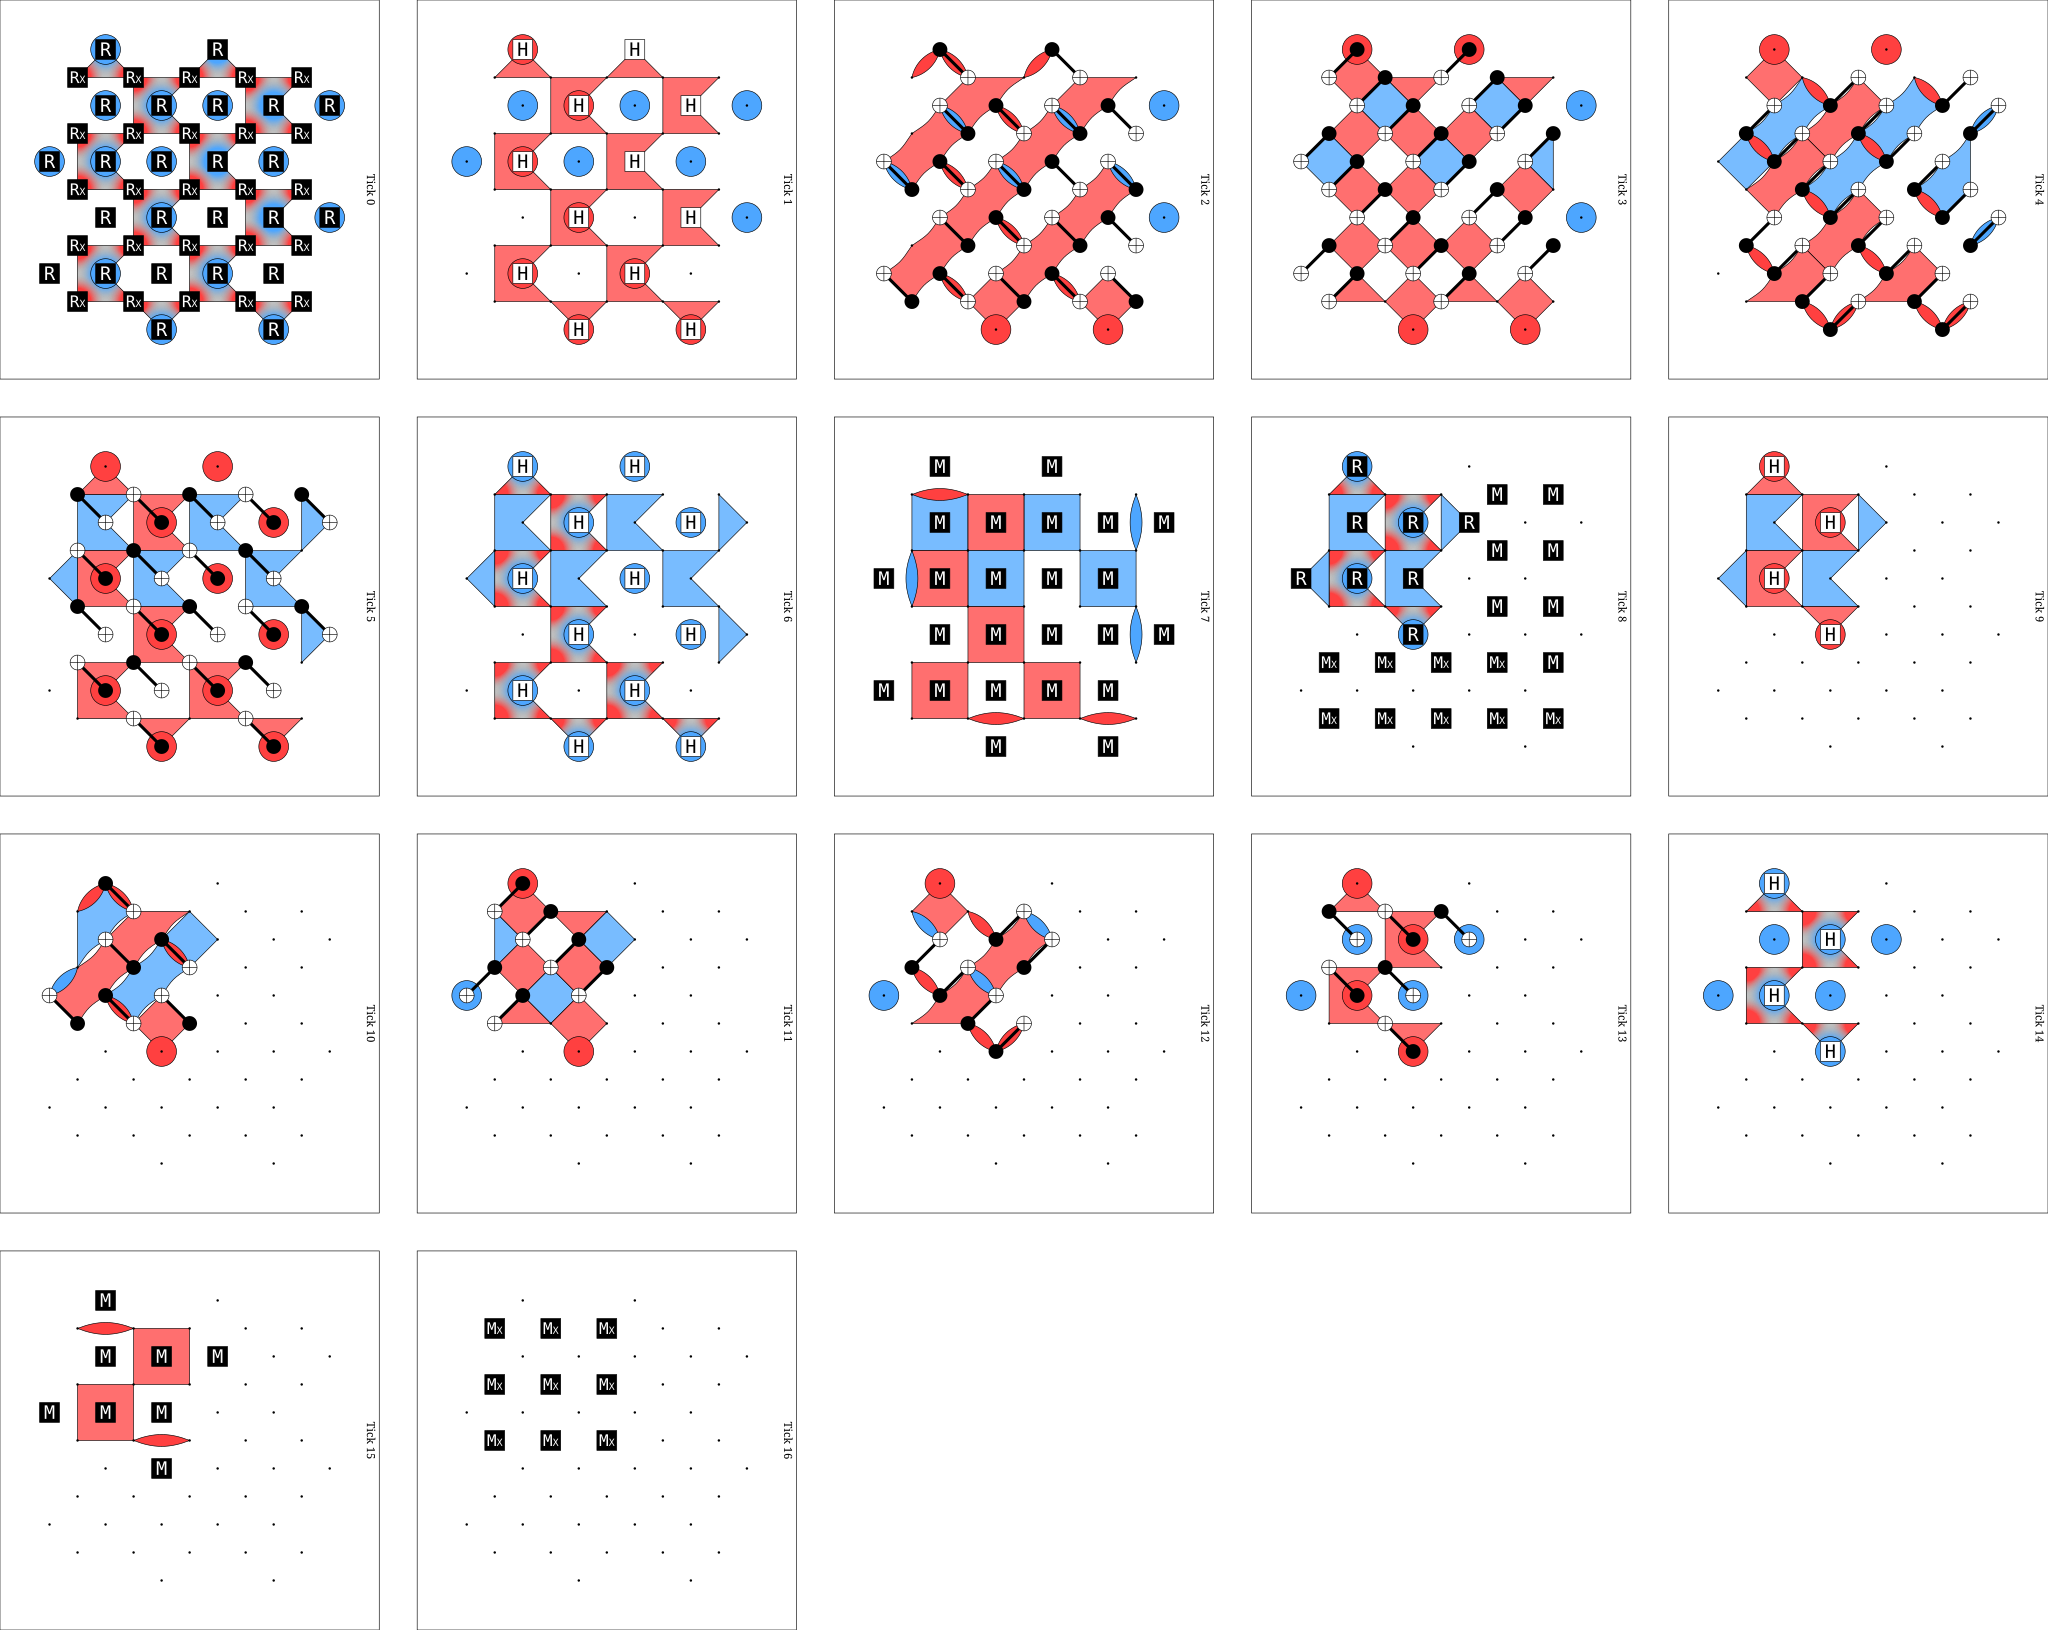

In [5]:
circuit.diagram("detslice-with-ops-svg")